# Body fat: choosing `mstop`

Each boosting iteration adds a small multiple of one base learner to the
predictor, so the iteration count sets how much structure the fitted model
carries. A fit stopped at 40 iterations and the same fit stopped at 1000 are
different models. Three rules choose the count: a fixed count set in advance, an information criterion
evaluated along the path, and cross-validation.

This study measures what each rule chooses on 71 observations, how far the
choice moves when the resampling is repeated, and what it costs on held-out
data.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how to choose the iteration count, which decides how much structure the model carries |
| **Observed response** | `DEXfat`, body fat measured by dual-energy X-ray absorptiometry (DEXA), in kg |
| **Estimand** | the stopping point itself: the iteration count each rule selects, and the held-out error that follows from it |
| **Units** | kg |
| **Sampling unit** | one woman |
| **Dependence** | treated as independent |
| **Split / resampling unit** | the woman |
| **Tuning** | the object of study: a fixed count of 100, the corrected AIC (Akaike's information criterion), ten-fold cross-validated risk and the one-standard-error rule are compared against each other |
| **Uncertainty** | the across-fold spread of the risk curve, twenty fold draws, and twenty 70/30 splits |
| **Claim type** | methodological |
:::


## The data

The `bodyfat` data set contains 71 healthy women from Garcia et al.,
distributed with R's `TH.data`. The response `DEXfat` is body fat in kg
measured by dual-energy X-ray absorptiometry (DEXA), and the nine predictors are age, four circumference and breadth
measurements, and four derived anthropometric indices. [](bodyfat.ipynb) uses
the same data for a different decision, whether the effects are curved.

Every predictor enters as a P-spline base learner, `bbs(x, df=4)`: a cubic
B-spline basis in that predictor with a penalty on differences between
neighbouring coefficients, set so that one fit of the learner has four
effective degrees of freedom. At each iteration boosting fits every base learner
to the current residuals and adds the best-fitting one, multiplied by the step
length 0.1, to the model. The fit runs to 1000 iterations.

The sample is 71 healthy women from one study; the stopping points and errors
reported here may differ for other populations and larger samples.

In [1]:
import warnings

import numpy as np
import polars as pl

import mboostrs as mb

data = mb.datasets.bodyfat(output="records")
predictors = [c for c in data if c != "DEXfat"]
n = len(data["DEXfat"])
terms = " + ".join(f"bbs({c}, df=4)" for c in predictors)

fit = mb.gamboost(f"DEXfat ~ {terms}", data=data, family=mb.Gaussian(),
                  control=mb.boost_control(1000, 0.1))

print(f"n = {n}, base learners = {len(predictors)}")
print(f"in-sample risk after  100 iterations {fit[:100].risk_[-1]:8.3f}")
print(f"in-sample risk after 1000 iterations {fit.risk_[-1]:8.3f}")

n = 71, base learners = 9
in-sample risk after  100 iterations  460.343
in-sample risk after 1000 iterations  266.977


The in-sample risk is the Gaussian loss summed over the training
observations, here the residual sum of squares over the 71 women. It falls at
every iteration: 460.343 after 100 iterations and 266.977 after 1000. Training risk therefore favors the longest path considered. Choosing a
shorter path requires a complexity penalty or an estimate of held-out risk.

## Three stopping rules: fixed, AIC and cross-validation

The fixed rule stops after a count set before the fit. R's `boost_control` and
`mboost` both default to 100; the Python `boost_control` takes the count as a
required argument.

`aic(method="corrected")` evaluates the corrected Akaike criterion at every
iteration. Its penalty is the effective number of parameters of the fit: the
trace of the boosting hat matrix, the matrix that maps the observed responses
to the fitted values after that many iterations. It uses the training data
only.

`cvrisk` refits the model with each of ten folds held out in turn and averages
the squared error per held-out observation, giving one risk curve over the
iteration count.

In [2]:
aic = fit.aic(method="corrected")
folds = mb.cv_weights(n, type="kfold", B=10, seed=1)
cv = fit.cvrisk(folds=folds)

print(f"fixed count               100 iterations")
print(f"corrected AIC             {aic.mstop:3d} iterations")
print(f"ten-fold cross-validation {cv.optimal_mstop:3d} iterations")

fixed count               100 iterations
corrected AIC              51 iterations
ten-fold cross-validation  43 iterations


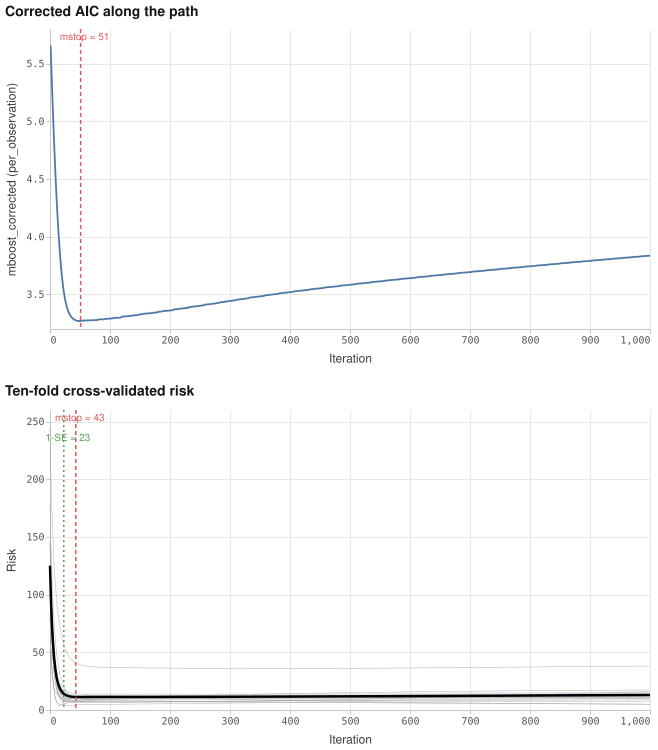

In [3]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    criterion_paths = (
        mb.plot.plot_aic(aic).properties(
            title="Corrected AIC along the path")
        & mb.plot.plot_cvrisk(cv).properties(
            title="Ten-fold cross-validated risk")
    )

criterion_paths

## Flatness of the cross-validated risk curve

The corrected AIC stops at 51 iterations and cross-validation at 43. The
distance between them is smaller than the width of the region the
cross-validated curve cannot separate.

In [4]:
grid = np.asarray(cv.grid)
mean_risk = np.asarray(cv.aggregate)
fold_risk = np.asarray(cv.risk_matrix)
best = int(np.argmin(mean_risk))
standard_error = fold_risk.std(axis=0, ddof=1) / np.sqrt(fold_risk.shape[0])
flat = grid[mean_risk <= mean_risk[best] * 1.01]

print(f"minimum {mean_risk[best]:.3f} at iteration {grid[best]}")
print(f"within 1% of the minimum: iterations {flat.min()} to {flat.max()}")
print(f"standard error of the fold average at the minimum "
      f"{standard_error[best]:.3f}, "
      f"{100 * standard_error[best] / mean_risk[best]:.0f}% of the risk")

minimum 11.217 at iteration 43
within 1% of the minimum: iterations 40 to 144
standard error of the fold average at the minimum 3.337, 30% of the risk


The minimum is 11.217 at iteration 43, and every iteration from 40 to 144 sits
within 1% of it. The standard error of the fold average at the minimum is
3.337, 30% of the risk. Ten folds of seven observations give each fold risk a
large sampling error, and averaging ten of them leaves a curve whose minimum is
a region rather than a point.

## Optimal `mstop` across fold draws

The fold assignment is a random draw. Repeating the cross-validation with
twenty draws gives twenty stopping iterations from the same data and the same
model.

In [5]:
draws = np.array([
    fit.cvrisk(folds=mb.cv_weights(n, type="kfold", B=10, seed=s)).optimal_mstop
    for s in range(1, 21)
])

print("stopping iteration by fold draw:", draws)
print(f"median {np.median(draws):.0f}, range {draws.min()} to {draws.max()}")

stopping iteration by fold draw: [ 43  40  45  48  38 319  66  55  40  45  40  43  45  52  58  68  67  59
  42  59]
median 46, range 38 to 319


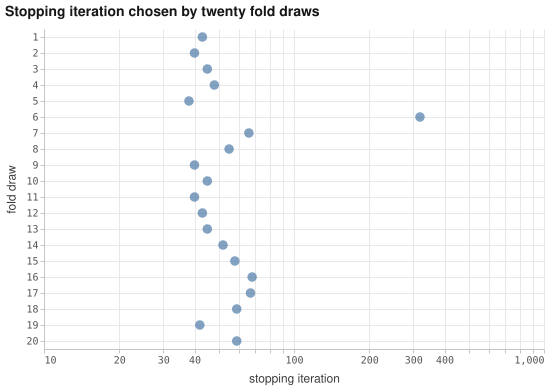

In [6]:
import altair as alt

draw_frame = pl.DataFrame({"draw": np.arange(1, len(draws) + 1), "mstop": draws})
alt.Chart(draw_frame).mark_circle(size=90, color="#4e79a7").encode(
    x=alt.X("mstop:Q", title="stopping iteration", scale=alt.Scale(type="log")),
    y=alt.Y("draw:O", title="fold draw"),
    tooltip=["draw:O", "mstop:Q"],
).properties(
    title="Stopping iteration chosen by twenty fold draws",
    width=500, height=320,
)

Nineteen of the twenty draws stop between 38 and 68 iterations. One stops at
319. Where the curve is flat, the difference between two candidate iterations
is smaller than the fold-to-fold variation in the average, so the location of
the minimum is set by which observations happened to fall together.

## Held-out error of each rule

The sample is split 70/30 twenty times. On each training part the model is
fitted to 1000 iterations, each rule chooses a stopping iteration from that
training part alone, and the squared error is measured on the held-out third.

A fourth rule is included: the smallest iteration whose cross-validated risk is
within one standard error of the minimum.

In [7]:
def one_standard_error(result):
    # Smallest iteration whose fold average is within one standard error
    # of the smallest fold average on the path.
    iterations = np.asarray(result.grid)
    average = np.asarray(result.aggregate)
    per_fold = np.asarray(result.risk_matrix)
    error = per_fold.std(axis=0, ddof=1) / np.sqrt(per_fold.shape[0])
    lowest = int(np.argmin(average))
    return int(iterations[int(np.argmax(average <= average[lowest] + error[lowest]))])

rng = np.random.default_rng(5)

records = []


In [8]:
for split in range(20):
    order = rng.permutation(n)
    n_train = int(0.7 * n)
    train = {k: v[order[:n_train]] for k, v in data.items()}
    test = {k: v[order[n_train:]] for k, v in data.items()}
    model = mb.gamboost(f"DEXfat ~ {terms}", data=train, family=mb.Gaussian(),
                        control=mb.boost_control(1000, 0.1))
    split_cv = model.cvrisk(folds=mb.cv_weights(n_train, type="kfold", B=10, seed=1))
    rules = {
        "fixed count": 100,
        "corrected AIC": model.aic(method="corrected").mstop,
        "cross-validation": split_cv.optimal_mstop,
        "one standard error": one_standard_error(split_cv),
        "no stopping": 1000,
    }
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        for rule, stop in rules.items():
            predicted = np.asarray(model[:int(stop)].predict(newdata=test)).ravel()
            records.append({
                "split": split,
                "rule": rule,
                "mstop": int(stop),
                "squared error": float(np.mean((test["DEXfat"] - predicted) ** 2)),
            })


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(kneebreadth), covariate kneebreadth: 1 below 8.1 (worst 0.24 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.24 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 4 learner(s) are asked to predict outside 

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 6 learner(s) are asked to predict outside the range they were fitted on. bbs(anthro3b), covariate anthro3b: 2 below 3.36 (worst 0.47 training ranges out); bbs(anthro4), covariate anthro4: 2 below 4.14 (worst 0.43 training ranges out); bbs(anthro3c), covariate anthro3c: 2 below 2.76 (worst 0.38 training ranges out); bbs(anthro3a), covariate anthro3a: 2 below 2.99 (worst 0.35 training ranges out); bbs(elbowbreadth), covariate elbowbreadth: 1 below 5.7 (worst 0.29 training ranges out); bbs(kneebreadth), covariate kneebreadth: 1 below 8.1 (worst 0.24 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.47 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to 

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(age), covariate age: 1 below 24 (worst 0.12 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.12 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they we

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(hipcirc), covariate hipcirc: 1 above 128.5 (worst 0.086 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.086 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:2136: ExtrapolationWarning: 2 learner(s) are asked to predict outside the 

In [9]:
summary = (
    pl.DataFrame(records)
    .group_by("rule")
    .agg(
        pl.col("mstop").median().alias("median mstop"),
        pl.col("mstop").min().alias("min mstop"),
        pl.col("mstop").max().alias("max mstop"),
        pl.col("squared error").mean().round(2).alias("mean squared error"),
        pl.col("squared error").median().round(2).alias("median squared error"),
    )
    .sort("mean squared error")
)
# Compute the table or diagnostic interpreted in the following paragraph.
display(summary)

wide = (
    pl.DataFrame(records)
    .pivot(on="rule", index="split", values="squared error")
)

paired = (wide["cross-validation"] - wide["corrected AIC"]).to_numpy()

print(f"cross-validation minus corrected AIC, per split: "
      f"mean {paired.mean():+.2f}, "
      f"standard error {paired.std(ddof=1) / np.sqrt(len(paired)):.2f}, "
      f"cross-validation lower in {int((paired < 0).sum())} of {len(paired)}")


rule,median mstop,min mstop,max mstop,mean squared error,median squared error
str,f64,i64,i64,f64,f64
"""corrected AIC""",51.0,38,100,11.44,10.5
"""fixed count""",100.0,100,100,11.79,10.72
"""cross-validation""",47.0,28,997,12.03,11.3
"""one standard error""",19.5,16,26,13.9,12.72
"""no stopping""",1000.0,1000,1000,14.33,14.14


cross-validation minus corrected AIC, per split: mean +0.59, standard error 0.26, cross-validation lower in 8 of 20


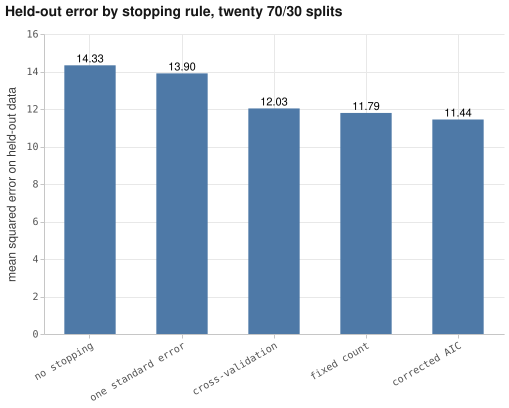

In [10]:
means = summary.select("rule", "mean squared error")
bars = alt.Chart(means).mark_bar(color="#4e79a7").encode(
    x=alt.X("rule:N", title=None, sort="-y", axis=alt.Axis(labelAngle=-30)),
    y=alt.Y("mean squared error:Q", title="mean squared error on held-out data"),
)
labels = alt.Chart(means).mark_text(dy=-6, fontSize=11).encode(
    x=alt.X("rule:N", sort="-y"),
    y=alt.Y("mean squared error:Q"),
    text=alt.Text("mean squared error:Q", format=".2f"),
)
alt.layer(bars, labels).properties(
    title="Held-out error by stopping rule, twenty 70/30 splits",
    width=460, height=300,
)

Running every fit to all 1000 iterations (the rule "no stopping") gives a mean
squared error of 14.33, against 11.44 for the corrected AIC, a difference of
2.89. The three ordinary rules lie within 0.59 of each other: 11.44 for the
corrected AIC, 11.79 for the fixed count of 100, and 12.03 for
cross-validation. The paired difference between cross-validation and the
corrected AIC is 0.59 with a standard error of 0.26 across the twenty splits,
and cross-validation gives the lower error in 8 of them.

The one-standard-error rule stops at a median of 19.5 iterations and costs
13.90. Its threshold is the minimum plus one standard error of the fold
average. On the full data that standard error is 3.337 against a minimum of
11.217, so the threshold is met by iterations at which the strongest effects
are still being fitted.

## Conclusions

Stopping matters more than the rule that does it. Across twenty 70/30 splits
the mean squared error was 14.33 without stopping, against 11.44, 11.79 and
12.03 for the corrected AIC, the fixed count of 100 and cross-validation.

The cross-validated minimum is a region at this sample size. Iterations 40 to
144 are within 1% of it, and across twenty fold draws the chosen iteration
ranged from 38 to 319.

Between the corrected AIC and cross-validation this sample does not choose. The
AIC's advantage is 0.59 in mean squared error with a paired standard error of
0.26, and cross-validation was lower in 8 of the 20 splits.

The one-standard-error rule is the more conservative choice and the worse one
here. It selected a median of 19.5 iterations and gave a mean squared error of
13.90, against 12.03 for the cross-validated minimum from which it is derived.

**Out of scope.** Gaussian loss with smooth learners on 71 observations.
`aic()` raises an error when a selected base learner has no hat matrix, as for
the monotone spline learner `bmono`, whose constrained fit is not a linear map
of the response. It also raises for the survival families, for multinomial
classification and for losses that are not log-likelihoods. The corrected
criterion is the Gaussian form.